In [1]:
import torch
import pandas as pd
import numpy as np
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer
from bertopic import BERTopic

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

/home/khushi/venvs/avenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
embeddings = np.load(
    "./embedding_epoch45/embeddings.npy"
)
df_text = pd.read_csv("./topic_modeling.csv")
df_text = df_text.iloc[:len(embeddings)].copy()
print("Rows with embeddings:", len(df_text))
docs = df_text["text"].fillna("").astype(str).tolist()

print("Final docs:", len(docs))
print("Final embeddings:", len(embeddings))

assert len(docs) == len(embeddings)

Rows with embeddings: 15690
Final docs: 15690
Final embeddings: 15690


In [3]:

# ---- dimensionality reduction tuned for neural embeddings ----
umap_model = UMAP(
    n_neighbors=60,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

# ---- clustering tuned for paragraph-scale dataset ----
hdbscan_model = HDBSCAN(
    min_cluster_size=120,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="leaf",
    prediction_data=True
)


custom_stopwords = list(ENGLISH_STOP_WORDS) + [
    "uh", "um", "okay", "thank", "yeah", "hi", "sign",
    "said", "like", "just", "also", "would", "one", "two",
    "three", "four", "five", "first", "second", "third",
    "got", "get", "going", "go", "know", "think", "say",
    "told", "tell", "asked", "came", "come", "went", "see"
]

vectorizer_model = CountVectorizer(
    stop_words=custom_stopwords,
    min_df=10,
    max_df=0.6,
    ngram_range=(1, 3)
)
ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)



topic_model = BERTopic(
    embedding_model=None,   
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    calculate_probabilities=True,
    ctfidf_model=ctfidf_model,
    verbose=True
)

topics, probs = topic_model.fit_transform(docs, embeddings)


2026-05-07 01:40:32,477 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
/home/khushi/venvs/avenv/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)
2026-05-07 01:41:13,001 - BERTopic - Dimensionality - Completed ✓
2026-05-07 01:41:13,003 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-05-07 01:41:14,422 - BERTopic - Cluster - Completed ✓
2026-05-07 01:41:14,428 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-05-07 01:41:18,107 - BERTopic - Representation - Completed ✓


In [4]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,7251,-1_multiplied_picture shows_factors_minus,"[multiplied, picture shows, factors, minus, sh...",[these might be small pieces of iron or we fin...
1,0,821,0_pattern_cotton_pointing_pwds,"[pattern, cotton, pointing, pwds, harassment, ...",[harassment complaint resolution proactive not...
2,1,599,1_segment_mann_rocks_kits,"[segment, mann, rocks, kits, box question, gif...",[after 7 0 years i have met you my heart is fa...
3,2,567,2_number written_cat_elephants_kilometers,"[number written, cat, elephants, kilometers, l...",[congress has won zero seats in 1 3 states he ...
4,3,443,3_tens_loose_acid_picture shows,"[tens, loose, acid, picture shows, palestine, ...",[the psalmavida kings sons had to perform a va...
5,4,434,4_akash_rakhi_robot_map,"[akash, rakhi, robot, map, angles, parade, int...",[in response to farmers' protests union minist...
6,5,403,5_toll_palace_diversity_rakhi,"[toll, palace, diversity, rakhi, saree, appoin...",[since they are younger more attractive and vi...
7,6,402,6_enable_hello_models_definitely,"[enable, hello, models, definitely, logo, taj,...",[however many do not believe in it it varies a...
8,7,383,7_pooja_telecom_conversion_clock,"[pooja, telecom, conversion, clock, statue, ma...",[it will premier on jio cinema how exciting yo...
9,8,376,8_nita_reader_files_item,"[nita, reader, files, item, movements, ships, ...",[c at equal distance from the center angles we...


In [5]:
topic_model.visualize_topics()

In [6]:
new_topics = topic_model.reduce_outliers(
    docs,
    topics,
)

topic_model.update_topics(docs, 
                           topics=new_topics,
                           vectorizer_model=vectorizer_model)

100%|██████████| 8/8 [00:06<00:00,  1.15it/s]
2026-05-07 01:47:38,574 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


In [7]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,3296,-1_classification_fraction_poultry_winds,"[classification, fraction, poultry, winds, tol...",[these might be small pieces of iron or we fin...
1,0,1034,0_cotton_pattern_fabric_sing,"[cotton, pattern, fabric, sing, coal, savings,...",[harassment complaint resolution proactive not...
2,1,794,1_segment_mann_rocks_page number,"[segment, mann, rocks, page number, scam, rule...",[after 7 0 years i have met you my heart is fa...
3,2,718,2_won seats_cat_number written_sequence,"[won seats, cat, number written, sequence, que...",[congress has won zero seats in 1 3 states he ...
4,3,577,3_matchsticks_picture shows_tens_loose,"[matchsticks, picture shows, tens, loose, tige...",[the psalmavida kings sons had to perform a va...
5,4,590,4_snake_integers_rakhi_robot,"[snake, integers, rakhi, robot, angles, graph,...",[in response to farmers' protests union minist...
6,5,555,5_toll_smoking_imran_abilities,"[toll, smoking, imran, abilities, imran khan, ...",[since they are younger more attractive and vi...
7,6,580,6_hello_logo_luck_courses,"[hello, logo, luck, courses, mental health, mo...",[however many do not believe in it it varies a...
8,7,549,7_statue_boss_auction_packages,"[statue, boss, auction, packages, pooja, ats, ...",[it will premier on jio cinema how exciting yo...
9,8,498,8_bones_reader_musk_triangle,"[bones, reader, musk, triangle, files, shift, ...",[c at equal distance from the center angles we...


In [12]:
topics_to_view = [1, 4, 6, 8, 17, 18, 21]

for topic in range(28):
    print(f"\n========== Topic {topic} ==========")

    docs = topic_model.get_representative_docs(topic)

    for i, doc in enumerate(docs, 1):
        print(f"\n--- Representative Doc {i} ---")
        print(doc[:1000])   # print first 1000 chars


========== Topic 0 ==========

--- Representative Doc 1 ---
harassment complaint resolution proactive not communicating or asking navin's behavior and not his intention office be mindful about your surrounding know you have done something wrong or sexual harassment or bos act let's learn he is not an employer of the office would was very uncomfortable with ram as he with most hearing colleagues by lip environment for example just brushing women i see to have a presiding officer colleagues she goes to another office as answer could ram have prevented this is the office place plus all the places appearance be mindful and conscious of threatening unfavorable treatment in 1 0 employees can seek the services of institutes to learn the skill of people let's learn how to seek close to her though sja felt answers institute learning computers and and has many deaf employees he person or at times wants to hold the granted and not being mindful about the mobility do you think the situation can p

In [8]:
topic_model.visualize_heatmap()

In [13]:
def label_topic(docs, client, batch_size=20):
    
    for start in range(0, len(docs), batch_size):

        batch = docs[start:start+batch_size]
        joined = "\n\n".join(batch)

        prompt = f"""
You are an expert at summarizing topics from clustered documents.

Your task is to assign a **clear and concise topic label** that describes the main theme shared by the documents.

Guidelines:
- The label must be **2–5 words only**
- Use **descriptive nouns**, not sentences
- Avoid filler words like: "uh", "okay", "thank", etc.
- Capture the **common subject or activity**
- Do NOT repeat phrases from a single document unless they represent the shared theme
- Prefer general concepts (e.g., "Indian Politics", "Math Education", "Technology Tutorials")
- Make sure the topic you give represents all the docs in general

Documents belonging to one topic:
{joined}

Return ONLY the topic name.
"""

        try:
            return client.generate(prompt)

        except Exception as e:
            if "PROHIBITED_CONTENT" in str(e):
                print(f"⚠️ Batch {start}-{start+batch_size} blocked. Trying next batch...")
                continue
            raise e

    return "Unlabeled Topic"



import time
import google.generativeai as genai


class GeminiKeyFailover:
    def __init__(self, api_keys, model="gemini-2.5-flash", max_retries=5):
        self.api_keys = api_keys
        self.model_name = model
        self.max_retries = max_retries
        self.key_index = 0

        self._configure_client()

    def _configure_client(self):
        key = self.api_keys[self.key_index]
        print(f"🔑 Using key {self.key_index+1}/{len(self.api_keys)}")
        genai.configure(api_key=key)
        self.model = genai.GenerativeModel(self.model_name)

    def _next_key(self):
        self.key_index += 1

        if self.key_index >= len(self.api_keys):
            raise RuntimeError(" All Gemini API keys exhausted")

        self._configure_client()

    def generate(self, prompt):
        retries = 0

        while retries < self.max_retries:
            try:
                response = self.model.generate_content(prompt)

                if response.text:
                    return response.text.strip()

                return ""

            except Exception as e:
                error_str = str(e)

                if "429" in error_str or "quota" in error_str.lower():
                    print(f"⚠️ Key {self.key_index+1} failed: {e}")
                    self._next_key()
                    retries += 1
                    continue

                if "retry_delay" in error_str:
                    delay = 5
                    print(f"⏳ Rate limited. Waiting {delay}s...")
                    time.sleep(delay)
                    retries += 1
                    continue

                raise e

        raise RuntimeError("Max retries exceeded")


topic_info = topic_model.get_topic_info()

rep_docs = {}
for topic_id in topic_info.Topic:
    if topic_id == -1:
        continue

    docs_for_topic = [
        doc for doc, t in zip(docs, topic_model.topics_)
        if t == topic_id
    ]

    rep_docs[topic_id] = docs_for_topic
client = GeminiKeyFailover(API_KEYS)

topic_names = {}

for topic_id in topic_model.get_topic_info()["Topic"]:
    if topic_id == -1:
        continue

    docs_for_topic = rep_docs[topic_id]

    try:
        name = label_topic(docs_for_topic, client)
    except RuntimeError as e:
        print(e)
        break

    topic_names[topic_id] = name
    print(topic_id, "→", name)

🔑 Using key 1/5
0 → News Events
1 → General Knowledge Entries
⚠️ Key 1 failed: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash
Please retry in 58.453120168s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, violations {
  quota_metric: "generativelanguage.googleapis.com/generate_content_free_tier_requests"
  quota_id: "GenerateRequestsPerDayPerProjectPerModel-FreeTier"
  quota_dimensions {
    key: "model"
    value: "gemini-2.5-flash"
  }
  quota_dimensions {
    key: "location"
    value: "global"
  }
  quota_value: 20
}
, retry_delay {
  seconds: 58
}
]
🔑 Using key 2/5
2 → Israel Can

In [15]:
# Only re-label the bad ones manually based on their keywords
# from your heatmap axis labels

manual_labels = {
    0:  "News Events",
    1:  "General Knowledge",
    2:  "Israel-Hamas Conflict & Indian Crime",
    3:  "Children's Measurement Activities",
    4:  "General Information",
    5:  "Indian Politics & Social Issues",        # toll_smoking_imran
    6:  "Current Events & Concepts",
    7:  "Deaf Community & Sign Language",         # statue_boss_bigg_boss
    8:  "Assorted Knowledge",
    9:  "Indian News Briefs",
    10: "Indian Politics and Law",
    11: "India-US Relations & Science",
    12: "Indian Current Events",
    13: "Maharashtra & Social Issues",
    14: "Indian General Knowledge",
    15: "Mathematics & Social Empowerment",       # balloons_sinha_volume
    16: "Science & Electricity",                  # bulb_mirror_circuit
    17: "General Knowledge Updates",
    18: "General News and Concepts",
    19: "Current and Historical Events",
    20: "Mathematics & Geometry",                 # multiplied_brackets
    21: "Informative Texts",
    22: "High-Profile Criminal Investigations",
    23: "Deaf Athlete & Education Policy",
    24: "Ecology and Social Affairs",
    25: "News and Events",
    26: "Current Affairs",
    27: "Sign Language & Space Exploration",      # moon_taj_vikram
}

In [17]:
topic_model.set_topic_labels(manual_labels)

In [19]:
topic_model.get_topic_info()

,Topic,Count,Name,CustomName,Representation,Representative_Docs
0,-1,3296,-1_classification_fraction_poultry_winds,-1_classification_fraction_poultry_winds,"[classification, fraction, poultry, winds, tol...",[these might be small pieces of iron or we fin...
1,0,1034,0_cotton_pattern_fabric_sing,News Events,"[cotton, pattern, fabric, sing, coal, savings,...",[harassment complaint resolution proactive not...
2,1,794,1_segment_mann_rocks_page number,General Knowledge,"[segment, mann, rocks, page number, scam, rule...",[after 7 0 years i have met you my heart is fa...
3,2,718,2_won seats_cat_number written_sequence,Israel-Hamas Conflict & Indian Crime,"[won seats, cat, number written, sequence, que...",[congress has won zero seats in 1 3 states he ...
4,3,577,3_matchsticks_picture shows_tens_loose,Children's Measurement Activities,"[matchsticks, picture shows, tens, loose, tige...",[the psalmavida kings sons had to perform a va...
5,4,590,4_snake_integers_rakhi_robot,General Information,"[snake, integers, rakhi, robot, angles, graph,...",[in response to farmers' protests union minist...
6,5,555,5_toll_smoking_imran_abilities,Indian Politics & Social Issues,"[toll, smoking, imran, abilities, imran khan, ...",[since they are younger more attractive and vi...
7,6,580,6_hello_logo_luck_courses,Current Events & Concepts,"[hello, logo, luck, courses, mental health, mo...",[however many do not believe in it it varies a...
8,7,549,7_statue_boss_auction_packages,Deaf Community & Sign Language,"[statue, boss, auction, packages, pooja, ats, ...",[it will premier on jio cinema how exciting yo...
9,8,498,8_bones_reader_musk_triangle,Assorted Knowledge,"[bones, reader, musk, triangle, files, shift, ...",[c at equal distance from the center angles we...


## Macro-Categories and Topics

| Macro-Category | Topics |
|----------------|-------|
| **Mathematics & Science Education** | 3, 15, 20, 23 |
| **Indian News & Current Affairs** | 2, 5, 9, 10, 12, 13, 14, 18, 19, 22, 24, 25, 26 |
| **Deaf Community & Sign Language** | 7, 11, 19, 27 |
| **General Knowledge & Mixed** | 0, 1, 4, 6, 8, 17, 21 |

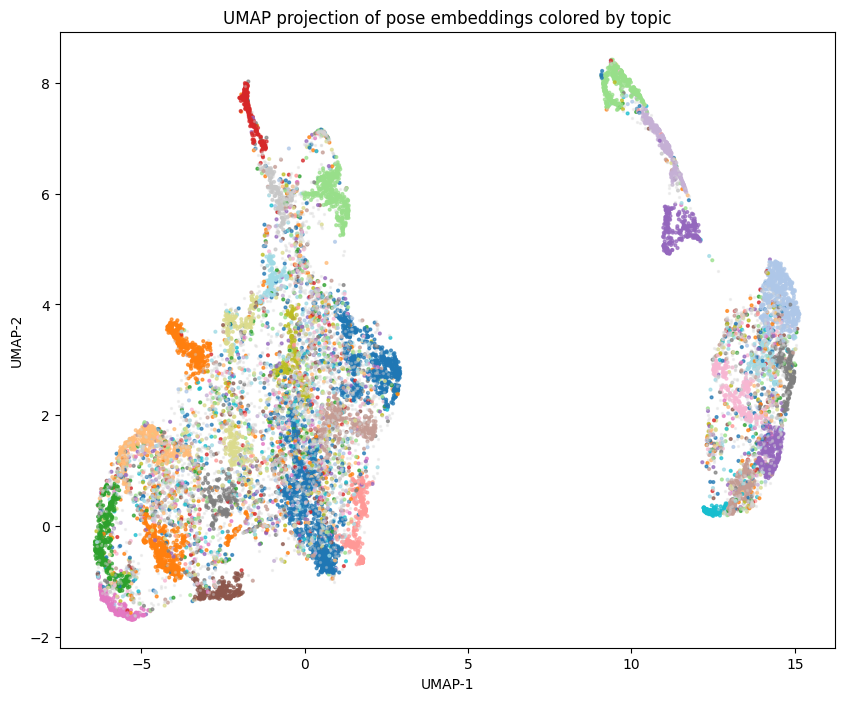

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from umap import UMAP

topics = np.array(topic_model.topics_)

umap_2d = UMAP(
    n_neighbors=60,
    n_components=2,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

emb_2d = umap_2d.fit_transform(embeddings)

plt.figure(figsize=(10,8))

# clusters
plt.scatter(
    emb_2d[topics!=-1,0],
    emb_2d[topics!=-1,1],
    c=topics[topics!=-1],
    cmap="tab20",
    s=4,
    alpha=0.7
)

# noise
plt.scatter(
    emb_2d[topics==-1,0],
    emb_2d[topics==-1,1],
    color="lightgray",
    s=2,
    alpha=0.3
)

plt.title("UMAP projection of pose embeddings colored by topic")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")

plt.savefig(
    "/data/dept_share/sanjeet/Khushi/topic_modeling/new03/umap_topics.pdf",
    bbox_inches="tight",
    dpi=300
)
